# Stage 7a: certified lower bounds on user-level ε from the existing audits, Enron, GPT-Neo 125M
**Plan:** section 4 row 7, first part (no GPU). Post-processing of Stage 2 (10 main seeds, null seed 0). The Stage 2 models are **not DP**
(true ε = ∞), so every number here measures **audit power**: the largest ε this audit could refute if the trainer claimed it.

Two routes, confidence 95%:
1. **TV inversion (Lemma 1):** ε ≥ log((1 + c − 2δ)/(1 − c)), c = DKW certificate. Shown for δ = 0 (δ = 1e-5 is identical to 3 decimals).
2. **One-run audit (Steinke et al. 2023), users as units.** Coins are independent and fair (`data/enron/splits.py`). Rank users by the statistic and guess on k
   of them: rule `sym` (k/2 top = member, k/2 bottom = non-member) or `top` (k top = member). ε is refuted if P[Bin(k, e^ε/(1+e^ε)) ≥ v] < β.
   **Pure-ε version**; the δ correction must be added before 7b. Grid of 14 (rule, k) pairs fixed in advance, Bonferroni β/14.
   `oracle` = best pair picked after seeing the labels: **not valid**, a reference only.

One test per model (draw 0 of the m-doc subsets). Null run and aggregator: EVAL users only.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import analysis as A
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
COL = {"T": "#2a78d6", "S_cat": "#eb6834", "Agg": "#1baf7a"}
MRK = {"T": "o", "S_cat": "s", "Agg": "^"}
NAME = {"T": "T̂ (mean)", "S_cat": "S_cat", "Agg": "aggregator (EVAL)"}
uv = A.S2.cached_user_values()
bm, gm = A.bounds(uv, "main"); bn, gn = A.bounds(uv, "null")
display(A.summarize(bm))

cert               eps_tv_d0               eps_tv_d1e-05               eps_1run               eps_1run_oracle              
                      mean    min    max      mean    min    max          mean    min    max     mean    min    max            mean    min    max
run  stat  users m                                                                                                                               
main Agg   EVAL  1  -0.057 -0.138  0.081     0.023  0.000  0.163         0.023  0.000  0.163    0.354  0.000  0.707           0.908  0.430  1.289
                 2  -0.009 -0.108  0.076     0.030  0.000  0.153         0.030  0.000  0.153    0.630  0.279  1.325           1.171  0.932  1.752
                 4   0.001 -0.109  0.122     0.068  0.000  0.245         0.068  0.000  0.245    0.483  0.187  1.016           1.030  0.588  1.416
                 8   0.059 -0.065  0.163     0.139  0.000  0.330         0.139  0.000  0.330    0.644  0.279  0.923           1.137  0.774  1.416
                 16  0.091 -0.058  0.203     0.199  0.000  0.411         0.199  0.000  0.411    0.818  0.279  1.193           1.391  1.052  1.823
                 32  0.102 -0.104  0.253     0.232  0.000  0.518         0.232  0.000  0.518    0.791  0.404  1.193           1.333  1.052  1.823
     S_cat all   1   0.046 -0.010  0.096     0.095  0.000  0.192         0.095  0.000  0.192    0.949  0.704  1.193           1.538  1.115  1.823
                 2   0.130  0.061  0.183     0.262  0.123  0.369         0.262  0.123  0.369    1.083  0.653  1.325           1.600  0.946  1.823
                 4   0.135  0.058  0.220     0.273  0.116  0.447         0.272  0.116  0.447    1.099  0.707  1.766           1.648  1.281  2.297
                 8   0.188  0.121  0.298     0.381  0.243  0.614         0.381  0.243  0.614    1.558  1.074  1.766           2.140  1.416  2.297
                 16  0.187  0.109  0.274     0.379  0.219  0.562         0.379  0.219  0.562    1.554  1.123  2.126           2.126  1.752  2.785
                 32  0.221  0.151  0.307     0.451  0.304  0.635         0.451  0.304  0.635    1.611  1.325  1.854           2.216  1.823  2.297
     T     all   1   0.046 -0.010  0.096     0.095  0.000  0.192         0.095  0.000  0.192    0.949  0.704  1.193           1.538  1.115  1.823
                 2   0.130  0.059  0.183     0.263  0.117  0.371         0.263  0.117  0.371    1.122  0.767  1.325           1.643  1.115  1.823
                 4   0.137  0.063  0.233     0.276  0.126  0.475         0.276  0.126  0.475    1.023  0.707  1.577           1.607  1.247  2.254
                 8   0.196  0.118  0.260     0.398  0.237  0.531         0.398  0.237  0.531    1.461  1.123  1.766           2.052  1.559  2.297
                 16  0.230  0.150  0.319     0.470  0.302  0.661         0.470  0.302  0.661    1.487  1.193  1.766           2.085  1.823  2.297
                 32  0.228  0.129  0.362     0.467  0.258  0.758         0.467  0.258  0.758    1.570  1.520  1.577           2.194  1.928  2.254

## 1. Null control (seed 0, EVAL users): every bound must be 0

In [2]:
display(bn[["stat", "m", "n1", "n0", "cert", "eps_tv_d0", "eps_1run", "eps_1run_oracle"]].round(3))
assert (bn.eps_tv_d0 == 0).all() and (bn.eps_1run == 0).all()

,stat,m,n1,n0,cert,eps_tv_d0,eps_1run,eps_1run_oracle
0,T,1,37,51,-0.348,0.0,0.0,0.0
1,S_cat,1,37,51,-0.348,0.0,0.0,0.0
2,Agg,1,37,51,-0.337,0.0,0.0,0.0
3,T,2,37,51,-0.380,0.0,0.0,0.0
4,S_cat,2,37,51,-0.373,0.0,0.0,0.0
5,Agg,2,37,51,-0.380,0.0,0.0,0.0
6,T,4,37,51,-0.327,0.0,0.0,0.0
7,S_cat,4,37,51,-0.297,0.0,0.0,0.0
8,Agg,4,37,51,-0.341,0.0,0.0,0.0
9,T,8,37,51,-0.360,0.0,0.0,0.0


## 2. Certified ε vs m, main run
Line: mean over 10 seeds; band: min–max over seeds. Solid: one-run (valid, Bonferroni); dashed: TV inversion.

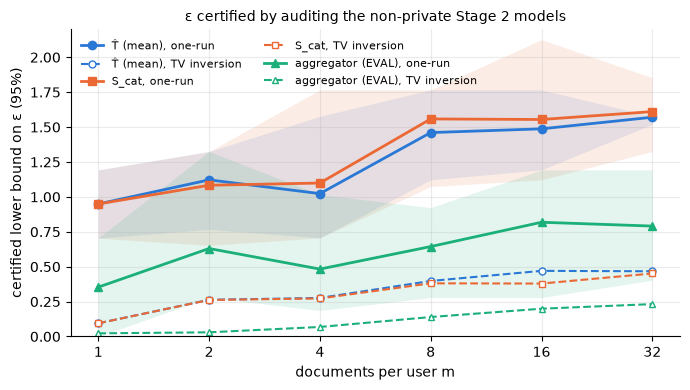

In [3]:
s = bm.groupby(["stat", "m"]).agg(tv=("eps_tv_d0", "mean"), tv_lo=("eps_tv_d0", "min"), tv_hi=("eps_tv_d0", "max"),
                                   r1=("eps_1run", "mean"), r1_lo=("eps_1run", "min"), r1_hi=("eps_1run", "max")).reset_index()
fig, ax = plt.subplots(figsize=(7, 4))
for st in A.STATS:
    x = s[s.stat == st]
    ax.fill_between(x.m, x.r1_lo, x.r1_hi, color=COL[st], alpha=.12, lw=0)
    ax.plot(x.m, x.r1, marker=MRK[st], color=COL[st], lw=2, ms=6, label=f"{NAME[st]}, one-run")
    ax.plot(x.m, x.tv, marker=MRK[st], color=COL[st], lw=1.5, ms=5, ls="--", mfc="white", label=f"{NAME[st]}, TV inversion")
ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8, 16, 32], [1, 2, 4, 8, 16, 32])
ax.set_xlabel("documents per user m"); ax.set_ylabel("certified lower bound on ε (95%)")
ax.set_title("ε certified by auditing the non-private Stage 2 models", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left"); ax.set_ylim(0, 2.2); plt.tight_layout(); plt.show()

## 3. Pooled over the 10 seeds (one-run)
Assumes every run satisfies the same ε, so it is meaningful for 7b's DP runs; here it shows what 10 runs could certify.

In [4]:
display(A.pooled(gm)[["m", "stat", "rule", "k", "seeds", "K", "V", "eps"]].round(2))

,m,stat,rule,k,seeds,K,V,eps
0,1,Agg,sym,10,10,100,93,1.60
1,1,S_cat,sym,10,10,100,98,2.27
2,1,T,sym,10,10,100,98,2.27
3,2,Agg,sym,20,10,200,177,1.46
4,2,S_cat,sym,10,10,100,99,2.51
5,2,T,sym,10,10,100,99,2.51
6,4,Agg,sym,10,10,100,93,1.60
7,4,S_cat,sym,10,10,100,100,2.85
8,4,T,sym,10,10,100,100,2.85
9,8,Agg,sym,10,10,100,95,1.82


## 4. The ceiling: best certifiable ε vs number of users (perfect attack)
Points: what T̂ at m = 32 certifies with 175 users (mean over seeds).

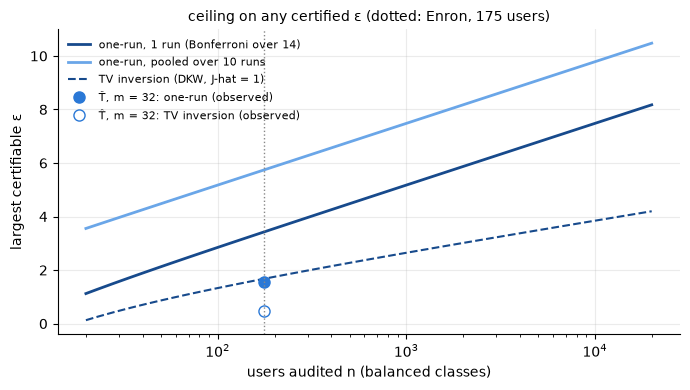

,n,cert_max,eps_tv_max,eps_1run_max_1runs,eps_1run_max_1runs_bonf,eps_1run_max_10runs,eps_1run_max_10runs_bonf
0,20,0.06,0.13,1.82,1.12,4.19,3.56
1,50,0.41,0.87,2.78,2.13,5.11,4.48
2,100,0.58,1.33,3.49,2.85,5.81,5.18
3,175,0.68,1.67,4.06,3.42,6.37,5.74
4,350,0.78,2.07,4.76,4.12,7.06,6.43
5,1000,0.87,2.65,5.81,5.18,8.11,7.48
6,3000,0.92,3.23,6.91,6.28,9.21,8.58
7,10000,0.96,3.85,8.11,7.48,10.42,9.78


,eps,adv_at_eps,users_tv,users_1run
0,0.5,0.244919,31,7
1,1.0,0.462117,61,10
2,2.0,0.761594,309,24
3,4.0,0.964028,13546,166
4,8.0,0.999329,38965303,8932


In [5]:
ce = A.ceilings(n_grid=np.unique(np.geomspace(20, 20000, 40).astype(int)))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ce.n, ce.eps_1run_max_1runs_bonf, color="#174a8c", lw=2, label="one-run, 1 run (Bonferroni over 14)")
ax.plot(ce.n, ce.eps_1run_max_10runs_bonf, color="#6aa6e8", lw=2, label="one-run, pooled over 10 runs")
ax.plot(ce.n, ce.eps_tv_max, color="#174a8c", lw=1.5, ls="--", label="TV inversion (DKW, J-hat = 1)")
t = bm[(bm.stat == "T") & (bm.m == 32)]
ax.plot([175], [t.eps_1run.mean()], "o", color=COL["T"], ms=8, label="T̂, m = 32: one-run (observed)")
ax.plot([175], [t.eps_tv_d0.mean()], "o", color=COL["T"], mfc="white", ms=8, label="T̂, m = 32: TV inversion (observed)")
ax.axvline(175, color="#888", lw=1, ls=":")
ax.set_xscale("log"); ax.set_xlabel("users audited n (balanced classes)"); ax.set_ylabel("largest certifiable ε")
ax.set_title("ceiling on any certified ε (dotted: Enron, 175 users)", fontsize=10)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
display(A.ceilings().round(2)); display(A.users_needed())

## Notes (2026-11-26)
- **Null:** every bound is 0 (EVAL users, all m and statistics). The procedure does not certify ε from a placebo.
- **Main, T̂ at m = 32, one model:** the one-run test certifies ε ≥ 1.57 (1.52–1.58 over seeds); the TV inversion ε ≥ 0.47 (0.26–0.76).
  The one-run route is about 3× stronger because it uses only the confident tails (it is a low-FPR test), while the TV route uses J at its best threshold.
  S_cat ≈ T̂; the aggregator is weaker (half the users).
- **Most seeds hit the grid ceiling:** 30/30 correct guesses gives 1.58 under Bonferroni. The audit is limited by the number of users, not the attack.
- **Pooled over 10 runs:** up to ε ≥ 3.2 (T̂) and 3.6 (S_cat) at m = 32. Only valid if all runs have the same ε.
- **Ceiling with 175 users (perfect attack):** 3.4 (one-run, one model, Bonferroni), 5.7 (10 runs), 1.7 (TV). Refuting ε = 8 with one run
  needs about 9,000 users, all guessed correctly; via TV, about 4·10⁷.
- **Consequence for 7b:** any DP run at nominal ε ≳ 3.5 is untestable here by construction. A 7b grid above about 4 can only show utility, not audit tightness.
- Open: the δ correction of the one-run bound; whether Lemma 1's adjacency (replace-one) matches the one-run bound's (add/remove).